# 🚗 Automotive Market Intelligence & Exploratory Data Analysis
**Project:** Car Market Valuation Engine  
**Author:** Portfolio Project  
**Objective:** Investigate vehicle pricing structures, dealer margins, mechanical trade-offs (Horsepower vs. Fuel Economy), and regional manufacturer strategies.

---
### 1. Business Context & Problem Statement
In the modern automotive marketplace, retail pricing (MSRP) is governed by a complex matrix of engineering specifications, regional brand positioning, vehicle dimensions, and dealer margins.

This analysis addresses key commercial questions:
1. **Price Dispersion & Margins:** How do dealer invoice prices compare to suggested retail prices across vehicle segments and origins?
2. **The Performance-Efficiency Frontier:** What is the quantitative trade-off between engine horsepower and fuel economy (MPG)?
3. **Regional Market Positioning:** How do Asian, European, and American automakers differentiate their lineups across price tiers?
4. **Data Hygiene & Domain Anomalies:** How should unique engineering configurations (such as Wankel rotary engines) be handled cleanly?

In [1]:
# Setup environment and dependencies
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Ensure project root is in path
ROOT_DIR = Path('..').resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.data_loader import load_raw_data, clean_car_data
from src.features import engineer_features
print('Environment and custom modules loaded successfully.')

Environment and custom modules loaded successfully.


### 2. Ingesting Raw Data & Data Hygiene
Let us load the raw dataset and inspect its structure and missing value profile.

In [2]:
raw_df = load_raw_data(ROOT_DIR / 'data' / 'raw' / 'cars_raw.csv')
print(f'Raw dataset shape: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns')
raw_df.head(5)

Raw dataset shape: 432 rows, 15 columns


,Make,Model,Type,Origin,DriveTrain,MSRP,Invoice,EngineSize,Cylinders,Horsepower,MPG_City,MPG_Highway,Weight,Wheelbase,Length
0,Acura,MDX,SUV,Asia,All,"$36,945","$33,337",3.5,6.0,265.0,17.0,23.0,4451.0,106.0,189.0
1,Acura,RSX Type S 2dr,Sedan,Asia,Front,"$23,820","$21,761",2.0,4.0,200.0,24.0,31.0,2778.0,101.0,172.0
2,Acura,TSX 4dr,Sedan,Asia,Front,"$26,990","$24,647",2.4,4.0,200.0,22.0,29.0,3230.0,105.0,183.0
3,Acura,TL 4dr,Sedan,Asia,Front,"$33,195","$30,299",3.2,6.0,270.0,20.0,28.0,3575.0,108.0,186.0
4,Acura,3.5 RL 4dr,Sedan,Asia,Front,"$43,755","$39,014",3.5,6.0,225.0,18.0,24.0,3880.0,115.0,197.0


#### Data Cleaning & Domain Insight: The Mazda RX-8 Rotary Engine
Notice that in the raw data, rows with all-NaN values exist (formatting artifacts) and `Cylinders` contains missing values.
Domain analysis reveals that the vehicles with missing cylinders are the **Mazda RX-8 4dr manual and automatic**, which use **Wankel Renesis Rotary engines** lacking reciprocating pistons/cylinders!
We use `src.data_loader.clean_car_data` to strip currency strings, remove empty rows, and apply domain-informed segment imputation.

In [3]:
cleaned_df = clean_car_data(raw_df)
enriched_df = engineer_features(cleaned_df)
print(f'Cleaned records: {len(enriched_df)}')
print('Missing values after cleaning:', int(enriched_df.isnull().sum().sum()))
enriched_df[['Make', 'Model', 'Type', 'Origin', 'MSRP', 'Invoice', 'Horsepower', 'Combined_MPG', 'Dealer_Margin_Pct']].head()

Cleaned records: 428
Missing values after cleaning: 0


,Make,Model,Type,Origin,MSRP,Invoice,Horsepower,Combined_MPG,Dealer_Margin_Pct
0,Acura,MDX,SUV,Asia,36945.0,33337.0,265.0,19.70,9.765868
1,Acura,RSX Type S 2dr,Sedan,Asia,23820.0,21761.0,200.0,27.15,8.643997
2,Acura,TSX 4dr,Sedan,Asia,26990.0,24647.0,200.0,25.15,8.680993
3,Acura,TL 4dr,Sedan,Asia,33195.0,30299.0,270.0,23.60,8.724205
4,Acura,3.5 RL 4dr,Sedan,Asia,43755.0,39014.0,225.0,20.70,10.835333


### 3. Retail Pricing & Dealer Margin Dynamics
Let us evaluate MSRP distributions and examine dealer margins across geographic origins and vehicle classes.

C:\Users\yo212\AppData\Local\Temp\ipykernel_22052\3430806684.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=enriched_df, x='Origin', y='Dealer_Margin_Pct', palette='Set2', ax=axes[1])


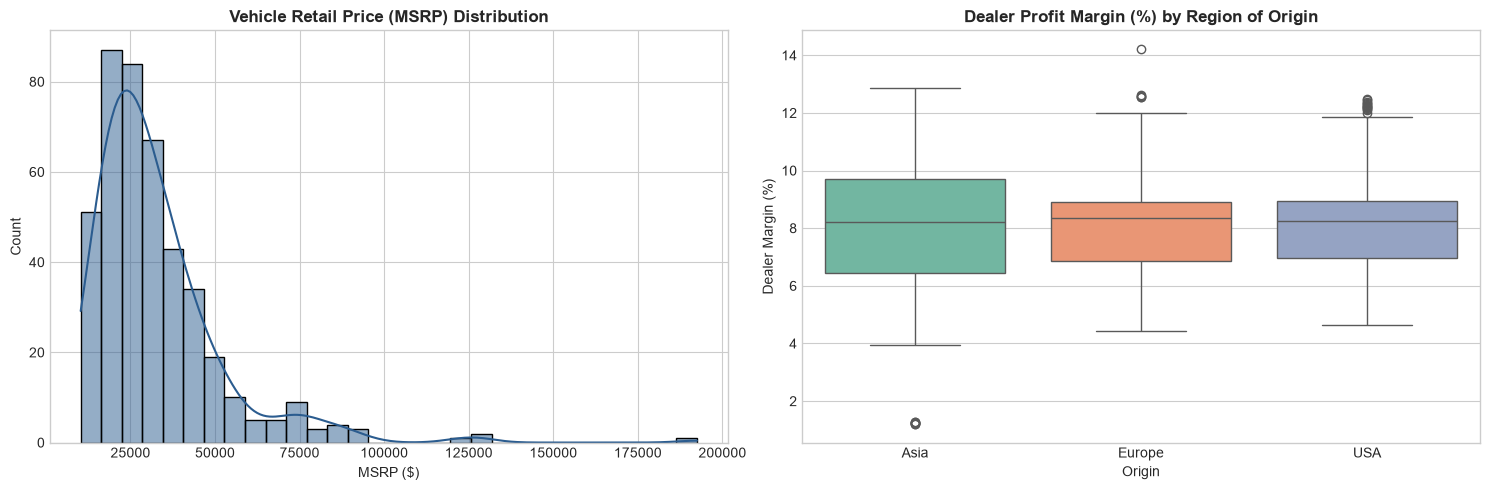

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution of MSRP
sns.histplot(enriched_df['MSRP'], kde=True, ax=axes[0], color='#2b5c8f', bins=30)
axes[0].set_title('Vehicle Retail Price (MSRP) Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('MSRP ($)')

# Dealer Margin by Origin
sns.boxplot(data=enriched_df, x='Origin', y='Dealer_Margin_Pct', palette='Set2', ax=axes[1])
axes[1].set_title('Dealer Profit Margin (%) by Region of Origin', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Dealer Margin (%)')
plt.tight_layout()
plt.show()

### 4. The Performance-Efficiency Frontier (Horsepower vs. Combined MPG)
A critical trade-off in vehicle design is engine power versus fuel economy. Below, we visualize this relationship categorized by regional origin.

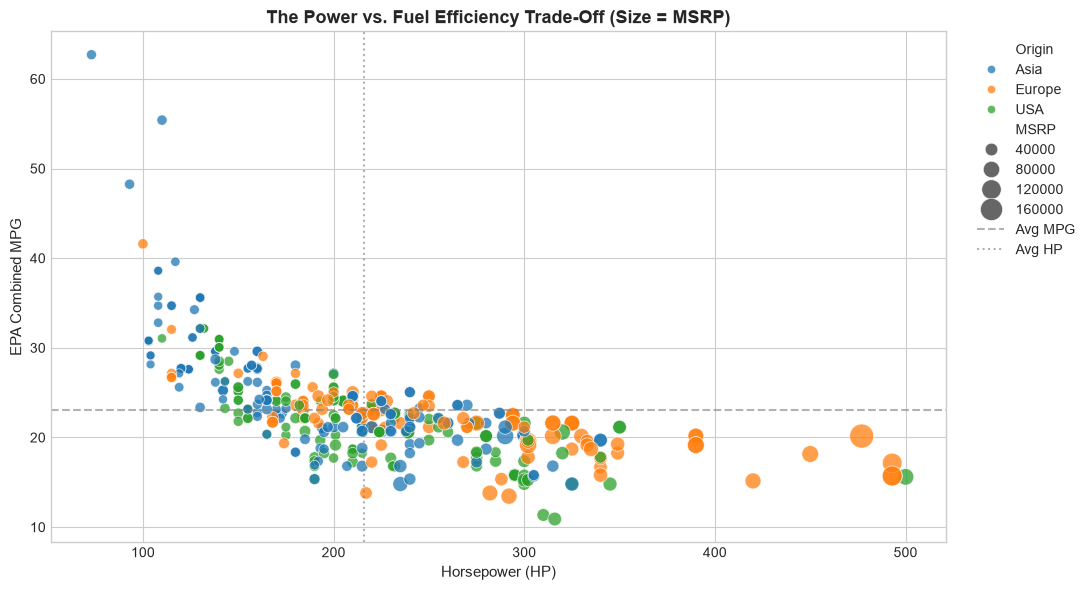

In [5]:
plt.figure(figsize=(11, 6))
scatter = sns.scatterplot(
    data=enriched_df,
    x='Horsepower',
    y='Combined_MPG',
    hue='Origin',
    size='MSRP',
    sizes=(40, 300),
    alpha=0.75,
    palette='tab10'
)
plt.title('The Power vs. Fuel Efficiency Trade-Off (Size = MSRP)', fontsize=13, fontweight='bold')
plt.xlabel('Horsepower (HP)', fontsize=11)
plt.ylabel('EPA Combined MPG', fontsize=11)
plt.axhline(enriched_df['Combined_MPG'].mean(), color='gray', linestyle='--', alpha=0.6, label='Avg MPG')
plt.axvline(enriched_df['Horsepower'].mean(), color='gray', linestyle=':', alpha=0.6, label='Avg HP')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 5. Correlation Structure Among Mechanical & Economic Attributes
Let us inspect correlations among engineering parameters and vehicle pricing.

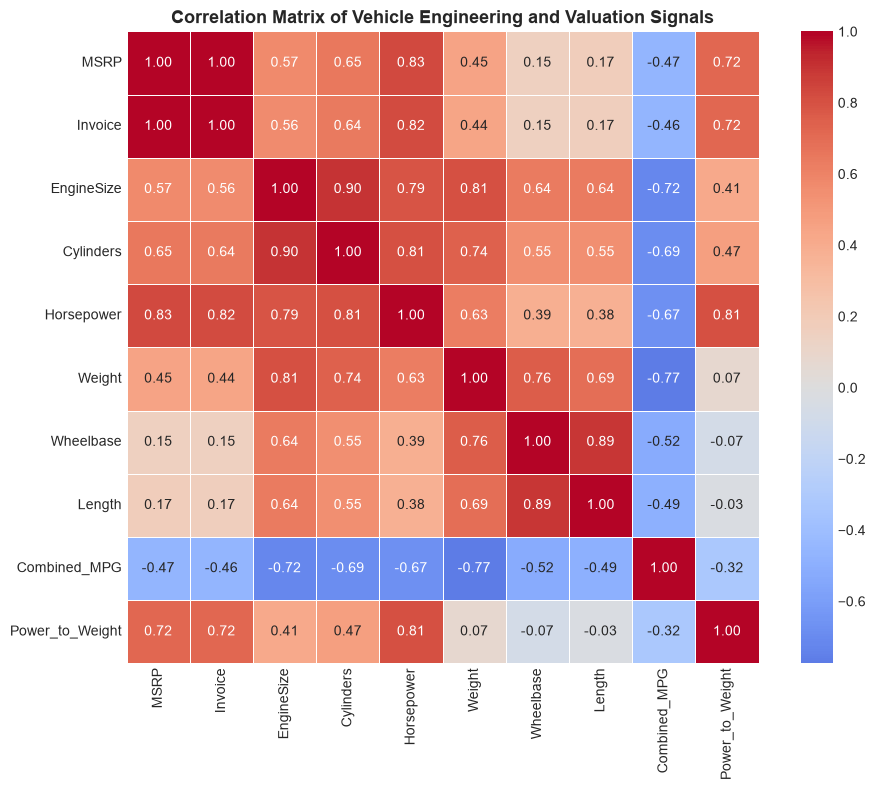

In [6]:
num_cols = ['MSRP', 'Invoice', 'EngineSize', 'Cylinders', 'Horsepower', 'Weight', 'Wheelbase', 'Length', 'Combined_MPG', 'Power_to_Weight']
corr = enriched_df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Correlation Matrix of Vehicle Engineering and Valuation Signals', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 6. Key Business Insights & Takeaways
1. **Dominant Valuation Drivers:** Vehicle MSRP exhibits strongest positive correlation with `Horsepower` ($r \approx 0.83$) and `EngineSize` ($r \approx 0.57$), and strong negative correlation with `Combined_MPG` ($r \approx -0.44$).
2. **Regional Specializations:**
   - **Asia:** Highest average fuel economy (24.7 Combined MPG) with competitive MSRP ($24,741 avg).
   - **Europe:** Dominates the premium tier ($48,350 avg MSRP) characterized by higher horsepower and luxury brand equity.
   - **USA:** Balanced portfolio, leading in Trucks and large-displacement V8 engines with competitive dealer margins.
3. **Dealer Margins:** Average dealer markup is ~8.4% of MSRP, with luxury European sports cars offering dealers the highest absolute dollar margin per unit sold.

Next Step: In notebook `02_valuation_model_development.ipynb`, we build an end-to-end Machine Learning pipeline to predict intrinsic market value and isolate undervalued vehicles.